In [1]:
%load_ext autoreload
%autoreload 2

# 02. Preprocessing, Training & Evaluation

## A. Load & Split

In [2]:
from src import laod_dataset, split_dataset
from src.config import RAW_DATA_PATH

df = laod_dataset(RAW_DATA_PATH, "student_mental_health.csv")
x_train, x_test, y_train, y_test = split_dataset(df)

print("Train shape:", x_train.shape)
print("Test shape:", x_test.shape)
print("Train target distribution:")
print(y_train.value_counts().to_string())
print("Test target distribution:")
print(y_test.value_counts().to_string())

Train shape: (1600, 15)
Test shape: (400, 15)
Train target distribution:
Mental_Health_Risk
High      544
Medium    528
Low       528
Test target distribution:
Mental_Health_Risk
High      136
Medium    132
Low       132


## B. Preprocessing Decisions

The split is **80/20 and stratified** on the target, so both sets keep the same class balance.

| Decision | Choice | Why |
|---|---|---|
| Missing numeric values | median imputation | robust to skewed features and outliers |
| Missing categorical values | most frequent imputation | keeps the dominant category without inventing a new one |
| Ordinal variables | `Physical_Activity` Low/Moderate/High and `Diet_Quality` Poor/Average/Good | the order carries information |
| Binary variables | `Part_Time_Job`, `Previous_Mental_Health_History` | No/Yes is mapped to 0/1 |
| Nominal variable | `Gender` one-hot encoded (first category dropped) | no natural order; dropping one avoids collinearity |
| Outliers | detected with IQR in the EDA, **kept** | the dataset documents them as realistic edge cases; `RobustScaler` limits their influence |
| Scaling | `RobustScaler` on numerical features | uses median/IQR, so extreme values do not dominate |
| Class imbalance | checked before training | SMOTE is only used if the max/min class ratio exceeds the threshold |

All transformations live inside a scikit-learn pipeline, so imputation, encoding, scaling and optional SMOTE are fitted on training folds only. This prevents data leakage.

In [3]:
from src import target_distribution, encode_target
from src.config import IMBALANCE_THRESHOLD

balance = target_distribution(df)
use_smote = balance["ratio to smallest class"].max() > IMBALANCE_THRESHOLD
print("Use SMOTE:", use_smote)

y_train = encode_target(y_train)
y_test = encode_target(y_test)

Target Distribution.
                    count  percentage  ratio to smallest class
Mental_Health_Risk                                            
Low                   660        33.0                     1.00
Medium                660        33.0                     1.00
High                  680        34.0                     1.03
Use SMOTE: True


## C. Baseline Models

Three classifiers are trained on the same training data: logistic regression, random forest and gradient boosting. Metrics are accuracy, weighted precision/recall/F1 and macro one-vs-rest ROC-AUC.

The table below is computed on the training set, so it is optimistic and only a sanity check; model selection uses 5-fold cross-validation in the next section.

Trained: logistic regression
Trained: random forest
Trained: gradient boosting
Models Metrics.
                     accuracy  precision  recall      f1  roc auc
logistic regression    0.7619     0.7637  0.7619  0.7627   0.9144
random forest          1.0000     1.0000  1.0000  1.0000   1.0000
gradient boosting      0.8988     0.8992  0.8988  0.8989   0.9799


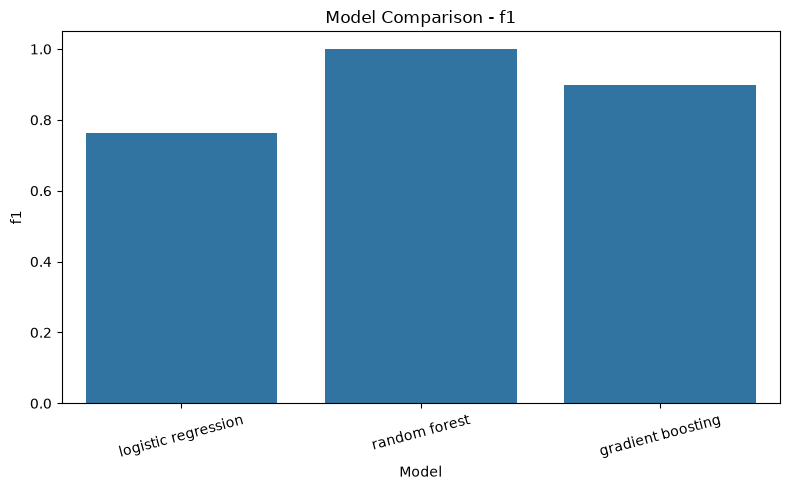

In [9]:
from src import train_models, evaluate_models, plot_model_comparison

baseline_models = train_models(x_train, y_train, use_smote)
baseline_report = evaluate_models(baseline_models, x_train, y_train, "baseline metrics.csv")
plot_model_comparison(baseline_report, filename="baseline model comparison.png")

## D. Hyperparameter Optimization

`GridSearchCV` tunes each pipeline with 5-fold cross-validation, scoring with weighted F1. The test set stays untouched during this step.

Optimized: logistic regression | best f1: 0.7488
Best params: {'classifier__C': 10}
Optimized: random forest | best f1: 0.6752
Best params: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}
Optimized: gradient boosting | best f1: 0.6948
Best params: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}
Optimization Report.
                    best cv f1                                                                                        best params
logistic regression     0.7488                                                                              {'classifier__C': 10}
random forest           0.6752  {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}
gradient boosting       0.6948    {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}


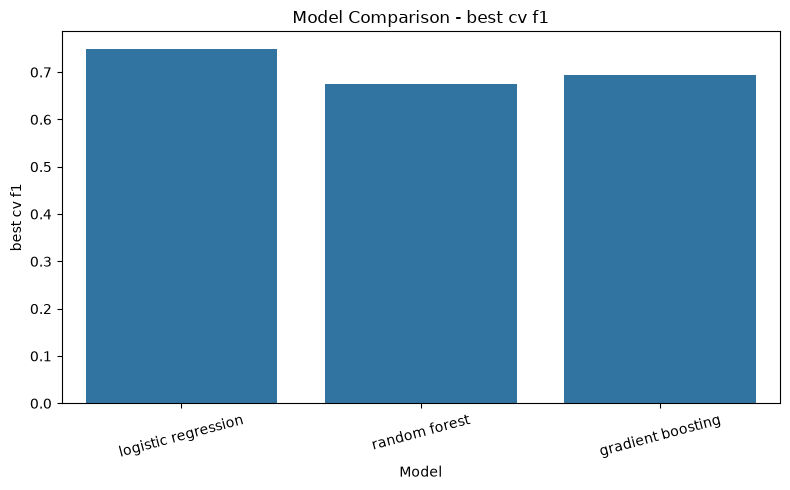

In [5]:
from src import optimize_models, optimization_report, plot_model_comparison

optimized_models = optimize_models(x_train, y_train, use_smote)
optimization_df = optimization_report(optimized_models)
plot_model_comparison(optimization_df, metric="best cv f1", filename="optimized model comparison.png")

## E. Model Selection

In [12]:
from src import select_best

best = select_best(optimized_models)

Best model: logistic regression
Best cv f1: 0.7488
Best params: {'classifier__C': 10}


## F. Final Test Evaluation

The selected pipeline is evaluated once on the independent test set. The confusion matrix, classification report and misclassified rows are saved under `reports/models/` and `figures/`.

Final Test Metrics.
                     accuracy  precision  recall      f1  roc auc
logistic regression      0.76     0.7596    0.76  0.7598   0.9139
Final Classification Report.
              precision  recall  f1-score  support
Low              0.8231  0.8106    0.8168   132.00
Medium           0.6412  0.6364    0.6388   132.00
High             0.8129  0.8309    0.8218   136.00
accuracy         0.7600  0.7600    0.7600     0.76
macro avg        0.7591  0.7593    0.7591   400.00
weighted avg     0.7596  0.7600    0.7598   400.00


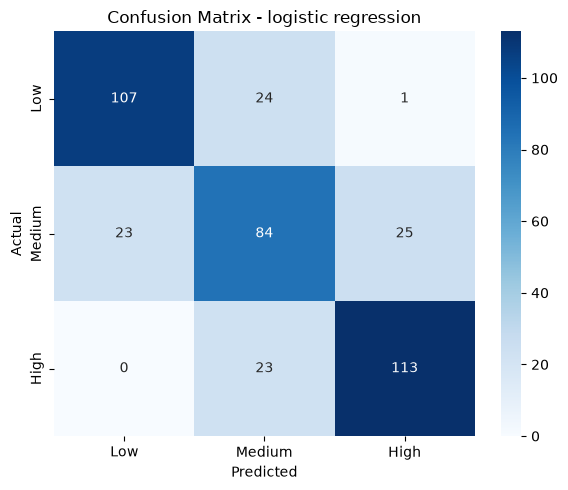

Misclassified rows: 96 / 400
predicted  High  Low  Medium
actual                      
High          0    0      23
Low           1    0      24
Medium       25   23       0


In [ ]:
from src import evaluate_final, analyze_errors

final_result = evaluate_final(best["model"], x_test, y_test, best["name"])
errors = analyze_errors(best["model"], x_test, y_test, best["name"])

## G. Save Full Pipeline

In [8]:
from src import save_model

save_model(best["model"], best["name"])

Model saved to: /home/brahim-44/Desktop/mental-health/models/final_model.joblib


## H. Results, Interpretation & Limits

First full run (seed 42, 80/20 split, 5-fold CV):

| Model | CV weighted F1 |
|---|---|
| logistic regression | 0.7476 |
| random forest | 0.6883 |
| gradient boosting | 0.6986 |

Selected model: **logistic regression** (`C=10`).

| Test metric | Value |
|---|---|
| accuracy | 0.7575 |
| weighted precision | 0.7584 |
| weighted recall | 0.7575 |
| weighted F1 | 0.7579 |
| macro OVR ROC-AUC | 0.9142 |

Per-class F1: Low 0.8168, Medium 0.6391, High 0.8162. The Medium class is the hardest, and all 97 misclassifications are between adjacent classes (Low <-> Medium or Medium <-> High); there are no Low <-> High errors. That is the safest failure mode for this use case.

Why logistic regression wins: the synthetic target is built from an approximately weighted additive score, and the EDA shows mostly monotonic, near-linear relationships (sleep -0.54, GPA -0.34, financial stress +0.31 with the encoded target). Tree models overfit the 1,600 training rows (random forest reaches 1.00 training accuracy) and generalize worse under cross-validation.

Limits:

- The dataset is synthetic and the target is engineered: scores confirm the documented generation logic, not real-world clinical validity.
- There is no temporal or external-cohort validation.
- Medium risk is confused with its neighbours, so a triage use case should treat it as "needs review" rather than a firm label.
- The model predicts a risk band, not a diagnosis; it should support, never replace, a human decision.
